<style>.jp-Notebook{max-width:960px;margin:0 auto} .jp-RenderedHTMLCommon table{font-size:13px}</style>

# Who Defines the Problem?

*A computational analysis of how the European Commission, Parliament and Council frame artificial intelligence regulation*

**Tim Maurice Steiner** and **Yuhan (Michelle) Qiu** · Instructor: Prof. Markus Neumann · SOSC 314, Duke Kunshan University, Fall 2026

[GitHub repository](https://github.com/michelle-qyh/SOSC314-Course-Project) · [Project website](https://michelle-qyh.github.io/SOSC314-Course-Project/)

> This is the notebook version of our final report. Text and figures are the same as on the project website; the tables are computed in this notebook directly from the result files in the repository. It is exported to `docs/report.html` with `jupyter nbconvert --to html --no-input`.

In [1]:
# Setup: paths and display helpers (code is hidden in the HTML export)
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name in ("report", "notebooks") else Path.cwd()
FIGS = ROOT / "docs" / "figures"
ANALYSIS = ROOT / "data" / "analysis"
TOPICS = ROOT / "reports" / "week5_topic_diagnostics"


def show(name, width=720):
    display(Image(filename=FIGS / name, width=width))


def table(df):
    display(df.style.hide(axis="index"))

## Summary

We read 139 official EU documents on AI with three computational methods and tested every difference we found. Most first impressions did not survive. Two did.

- **Frame dictionary: 8.0%** (95% interval 6.0–10.3 · others 3.7% and 3.1%). The Commission gives security and geopolitics more weight in its framing than the Parliament or the Council.

- **Topic model: 19.9%** (95% interval 11.6–29.1 · Parliament 5.8%). The Council writes far more about the AI Act's rules for high-risk systems than the Parliament does.

Both patterns follow what each institution's job requires it to write. They describe the texts, not the institutions' preferences.

## 01 · Research question

### One technology, many possible policy problems

Political institutions do not only respond to problems; they help define them. Framing means selecting some aspects of an issue and making them more salient, so that a particular definition of the problem, and a particular solution, starts to look natural (Entman 1993). Artificial intelligence can be framed as an engine of growth, a threat to fundamental rights, a security risk, a question for workers, or a matter of standards and compliance. Which framing dominates shapes which responses seem appropriate (Rochefort & Cobb 1994).

The European Union is a good place to study this, because three institutions with very different roles all wrote about the same law, the AI Act (Regulation (EU) 2024/1689):

| Institution | Role in EU law-making                             |
|-------------|---------------------------------------------------|
| Commission  | Executive; proposes legislation and implements it |
| Parliament  | Directly elected; co-legislator                   |
| Council     | Governments of the member states; co-legislator   |

> **Research question:** Does an institution's role in the EU system predict how it frames AI as a policy problem?

#### What we expected

| \#  | Institution | Expected to emphasise relatively more…                            |
|-----|-------------|-------------------------------------------------------------------|
| H1  | All three   | Systematically different frame profiles                           |
| H2  | Commission  | Regulatory governance, economic policy, technological development |
| H3  | Parliament  | Fundamental rights, consumer protection, social consequences      |
| H4  | Council     | Security, competitiveness, implementation by member states        |

We treated these as expectations to test, not assumptions to confirm: a result against them counts as a finding.

## 02 · Data

### 139 official EU documents on AI, 2020–2026

All documents come from official EU repositories. The main source is **CELLAR**, the database of the EU Publications Office behind EUR-Lex, which tags documents by subject. We collected every document tagged *artificial intelligence* (or with "artificial intelligence" in its title) from 2020 onward, and added 9 Council documents from the Council's public register and 5 Parliament texts from its Open Data Portal.

We kept only texts in which an institution states or negotiates its own position: Commission communications and staff documents, Parliament resolutions and reports, Council notes and conclusions. Adopted laws were left out because all institutions sign them, and so were studies, minutes and notes that only forward someone else's text.

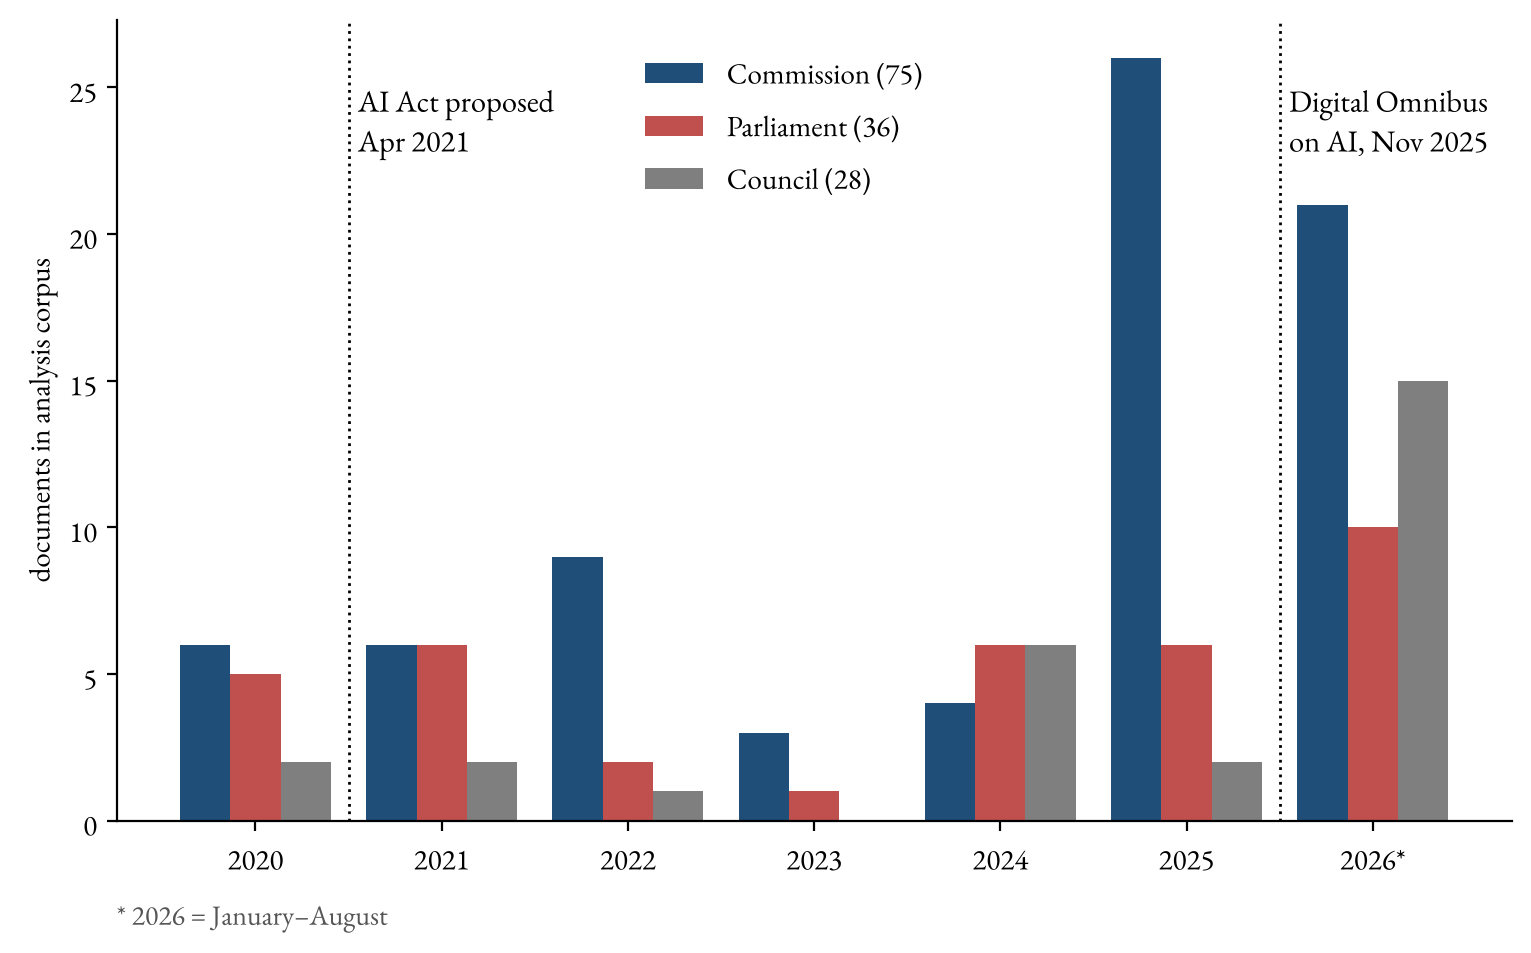

In [2]:
show("corpus_by_year.png")

**Figure 1.** Documents in the analysis corpus by year and institution. In total 139 documents, 27,732 paragraphs and 2.04 million words.

#### What we could not collect

Coverage is uneven. The Commission's documents are almost complete, but many Parliament committee opinions and amendment lists are listed in CELLAR without a downloadable text, and the Parliament website does not serve them to automated requests. We did not try to get around this. A screen for relevance then removed documents that mention AI only in passing (fewer than 0.5 mentions per 1,000 words) or are too short (under 200 words).

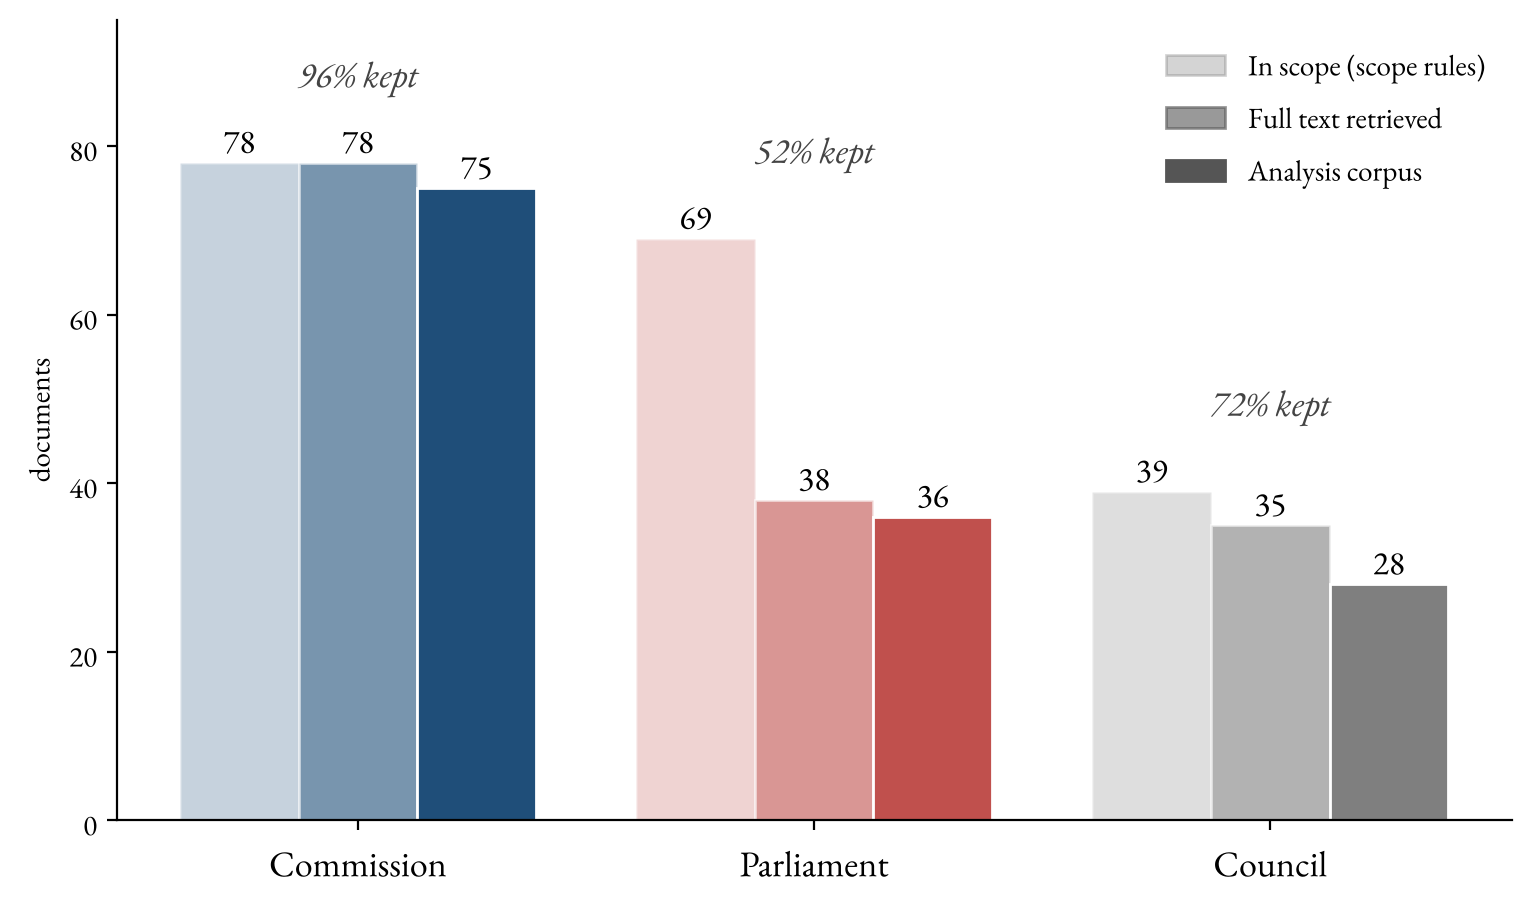

In [3]:
show("corpus_attrition.png", width=820)

**Figure 2.** Documents kept at each stage: in scope under our rules, full text retrieved, and final analysis corpus. Parliament and Council results therefore rest on fewer documents and carry more uncertainty.

#### What we measure

Long institutional documents mix several themes, so we measure at the level of the **paragraph** (median 49 words). Paragraph scores are averaged into a document score, and document scores into an institution score, so that every document counts equally however long it is.

## 03 · Methods

### Three routes to the same question

Each method can go wrong in its own way. A result that shows up in more than one of them is more convincing than any single one.

**Fightin' Words** (Baseline). Which single words separate two institutions? A log-odds comparison with a statistical prior that keeps rare words from topping the list by chance (Monroe, Colaresi & Quinn 2008). **Imposes:** no categories.

**Seven-frame dictionary** (Main measure). 152 words sorted into the seven frames from our proposal. Each paragraph is scored as frame words per 100 words; each institution's profile is the share of its framing that goes to each frame (the seven shares add up to 100%). **Imposes:** our categories.

**Topic models** (Cross-check). LDA and NMF find groups of words that occur together in the same paragraphs ("topics"); we read and name them afterwards. Ten topics, chosen by how coherent their top words are. **Imposes:** no categories.

#### The first lesson: style before substance

On raw text, Fightin' Words separates the institutions almost perfectly, but by document style, not framing. The Parliament's most distinctive words are *regard, calls, whereas, stresses*, the grammar of a resolution; the Council's are *article, annex, paragraph, pursuant*, the grammar of a legal text. Only after removing such procedural and rhetorical words do substantive differences appear: the Parliament's *technologies, human, ethical, research* against the Council's *harmonisation, testing, conformity*. That cleaning decision alone replaces 30% of the most distinctive words, so we report it openly rather than hide it.

## 04 · Results

### What first appeared

The first dictionary profile seemed to fit our expectations well. The Commission was highest on technology and the economy; the Parliament was highest on fundamental rights and consumer protection, as H3 predicted; the Council was highest on regulatory governance and lowest on security.

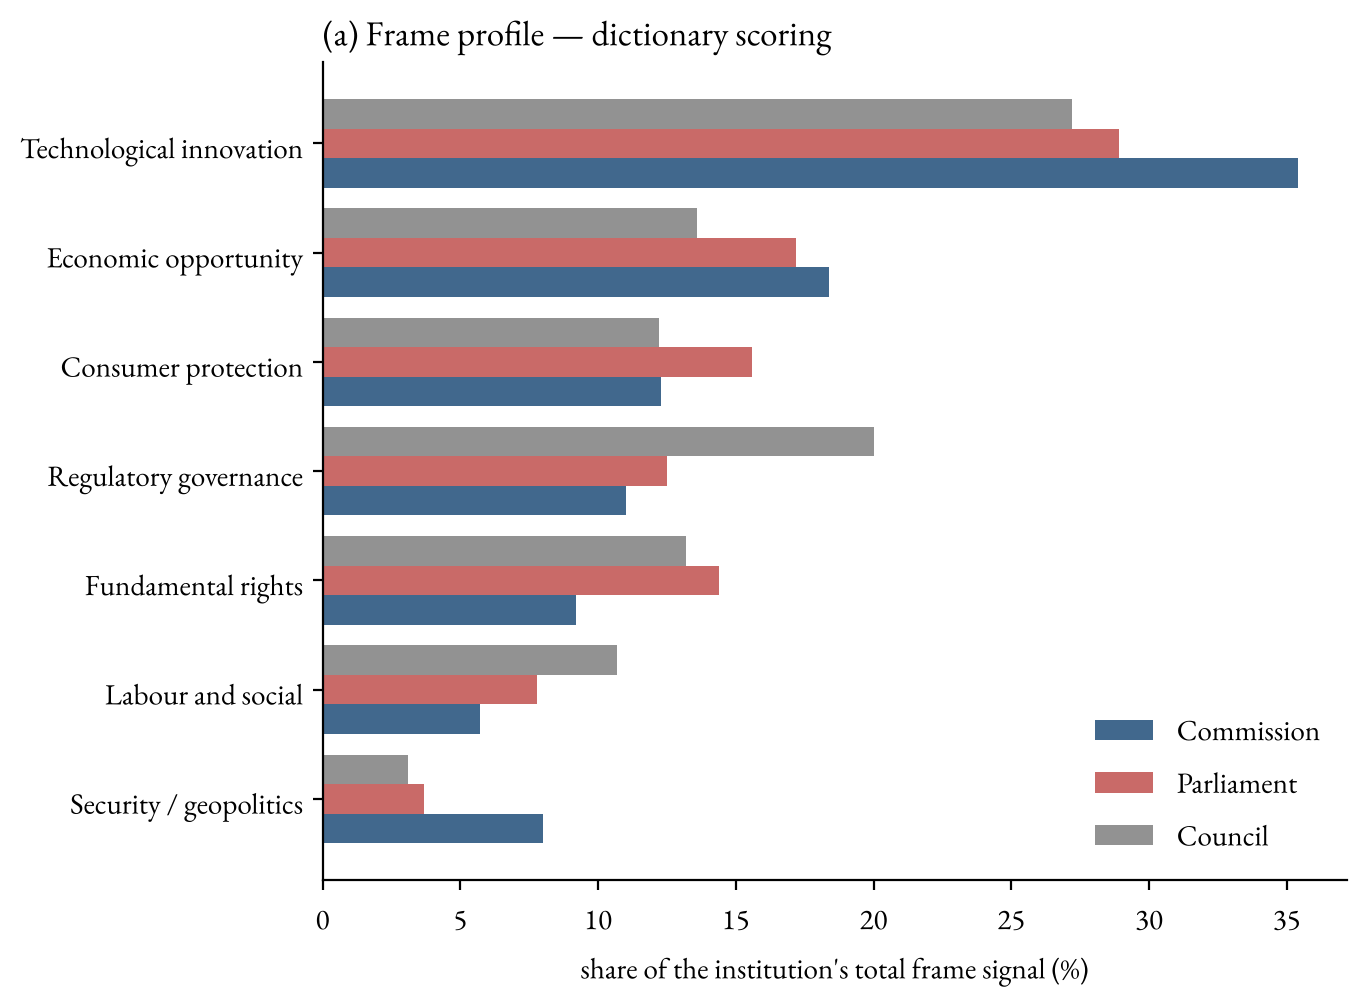

In [4]:
show("frame_profile.png")

**Figure 3.** Frame profile by institution. Each bar is the share of the institution's total frame vocabulary that belongs to that frame; each institution's seven bars add up to 100%.

#### With uncertainty added, one difference remains

Each institution has only 28 to 75 documents. To see how much a result depends on which particular documents an institution happened to write, we used a **bootstrap**: we redrew each institution's documents at random, with replacement, 1,000 times and recomputed the profile each time. The line around each dot covers the middle 95% of those results. We count a difference only if an institution's line does not overlap the others'.

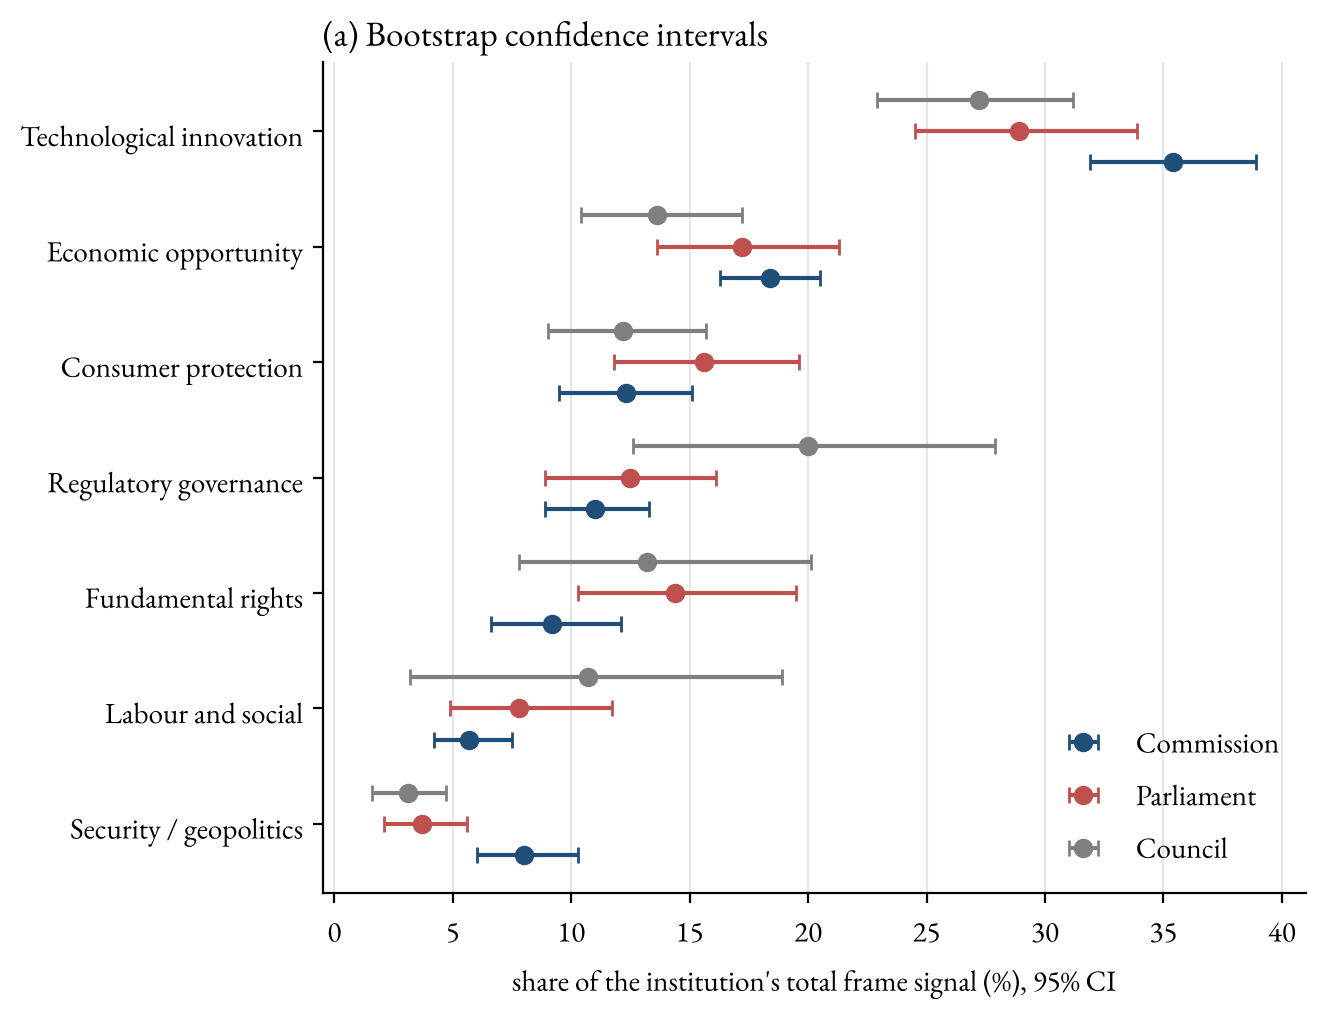

In [5]:
show("bootstrap.png")

**Figure 4.** Frame shares with 95% bootstrap intervals from 1,000 resamples of documents within each institution. The dot is the observed share.

In [6]:
# Table 1: frame shares with 95% bootstrap intervals (data/analysis/bootstrap_frame_profile.csv)
boot = pd.read_csv(ANALYSIS / "bootstrap_frame_profile.csv")
boot["share"] = boot.apply(lambda r: f"{r.point:.1f}  [{r.ci_low:.1f}, {r.ci_high:.1f}]", axis=1)
names = {"technological_innovation": "Technological innovation", "economic_opportunity": "Economic opportunity",
         "consumer_protection": "Consumer protection", "regulatory_governance": "Regulatory governance",
         "fundamental_rights": "Fundamental rights", "labour_social": "Labour and social",
         "security_geopolitical": "Security / geopolitics"}
t1 = boot.pivot(index="frame", columns="institution", values="share").loc[list(names)]
t1 = t1[["Commission", "Parliament", "Council"]].rename(index=names)
t1.index.name = "Frame"
table(t1.reset_index())

Frame,Commission,Parliament,Council
Technological innovation,"35.4 [31.9, 38.9]","28.9 [24.5, 33.9]","27.2 [22.9, 31.2]"
Economic opportunity,"18.4 [16.3, 20.5]","17.2 [13.6, 21.3]","13.6 [10.4, 17.2]"
Consumer protection,"12.3 [9.5, 15.1]","15.6 [11.8, 19.6]","12.2 [9.0, 15.7]"
Regulatory governance,"11.0 [8.9, 13.3]","12.5 [8.9, 16.1]","20.0 [12.6, 27.9]"
Fundamental rights,"9.2 [6.6, 12.1]","14.4 [10.3, 19.5]","13.2 [7.8, 20.1]"
Labour and social,"5.7 [4.2, 7.5]","7.8 [4.9, 11.7]","10.7 [3.2, 18.9]"
Security / geopolitics,"8.0 [6.0, 10.3]","3.7 [2.1, 5.6]","3.1 [1.6, 4.7]"


**Table 1.** Frame shares (%) by institution, with 95% bootstrap intervals from 1,000 resamples of documents. Source: `data/analysis/bootstrap_frame_profile.csv`.

Only the Commission's lead on security survives (8.0%, interval 6.0–10.3; the others' intervals end at 5.6 and 4.7). The Commission's technology lead overlaps with the Parliament, the Council's governance lead spans 12.6 to 27.9% on just 28 documents, and the Parliament's rights lead overlaps with the Council.

#### The topic models: a difference in content

In the first topic model, two governance-related topics, national enforcement authorities and requirements for high-risk AI systems, together made up 54.5% of the Council's topic weight. In the revised model (after we changed the text cleaning), the high-risk topic alone made up 41.6% of the Council's topic weight when every paragraph counts. But long Council compromise texts counted with all their paragraphs. Giving every document equal weight, as the dictionary does, cut this to 19.9%; yet it still clearly exceeds the Parliament's (interval 11.6–29.1 against 2.8–9.8).

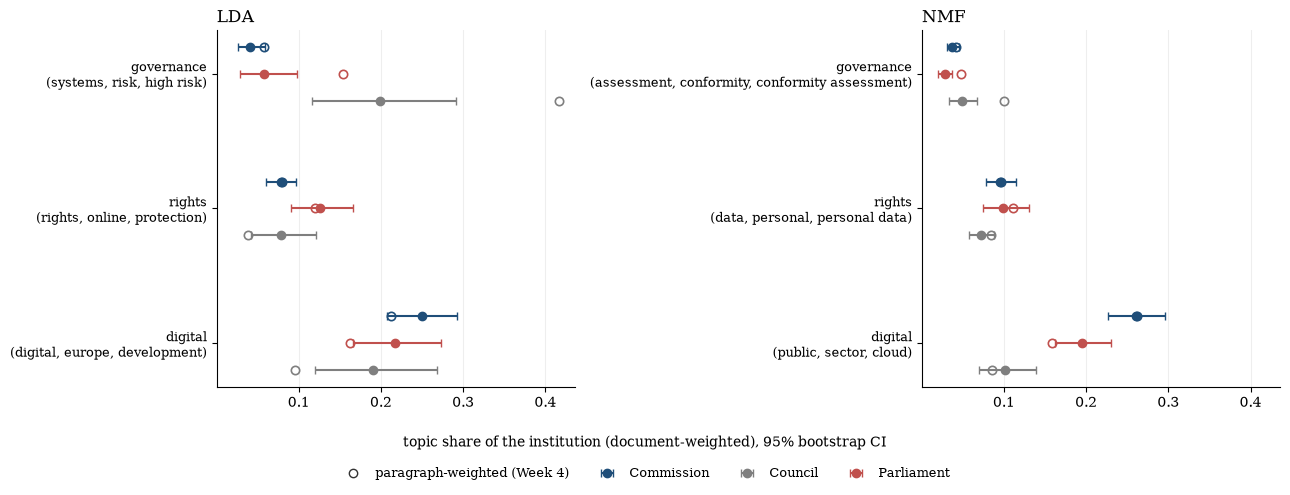

In [7]:
show("topics_bootstrap.png", width=940)

**Figure 5.** The three tracked topics in LDA (left) and NMF (right): document-weighted shares with 95% bootstrap intervals; hollow markers show the same model weighted by paragraph (the Week 4 method). In LDA, the topic labelled "governance" is the high-risk topic discussed in the text. Topics with the same label in LDA and NMF were chosen separately by their keywords and are not the same topic: NMF splits the high-risk rules into several smaller topics, and its "governance" topic (conformity assessment) is one of them. NMF has no clean rights topic, so data protection stands in.

The high-risk topic also came back in all six re-runs of the model from different random starting points, and the Council still led when we asked for twenty topics instead of ten. The rights topic, by contrast, came back in none of the six re-runs.

In [8]:
# Table 2: stability of the three tracked LDA topics
# (seed_stability.csv, k20_check.csv, preprocessing_check.csv in reports/week5_topic_diagnostics/)
seed = pd.read_csv(TOPICS / "seed_stability.csv")
k20 = pd.read_csv(TOPICS / "k20_check.csv")
prep = pd.read_csv(TOPICS / "preprocessing_check.csv")
yes_no = {True: "yes", False: "no"}
rows = []
for name, t in {"High-risk systems": 7, "Rights": 8, "Digital": 5}.items():
    s = seed[seed.topic == t].iloc[0]
    k = k20[(k20.model == "LDA") & (k20.topic == t)].iloc[0]
    p = prep[(prep.model == "LDA") & (prep.topic == t)].iloc[0]
    rows.append({"LDA topic": f"{name} (T{t})",
                 "Re-runs matched (of 6)": int(round(s.share_runs_matched * 6)),
                 "Similarity at 20 topics": f"{k.family_cos:.3f}",
                 "Same leader at 20 topics": yes_no[bool(k.same_leader)],
                 "Similarity after cleaning change": f"{p.cosine:.3f}",
                 "Same leader after cleaning change": yes_no[bool(p.same_leader)]})
table(pd.DataFrame(rows))

LDA topic,Re-runs matched (of 6),Similarity at 20 topics,Same leader at 20 topics,Similarity after cleaning change,Same leader after cleaning change
High-risk systems (T7),6,0.954,yes,0.851,yes
Rights (T8),0,0.584,no,0.475,no
Digital (T5),4,0.925,no,0.831,yes


**Table 2.** Stability of the three tracked LDA topics. Similarity is the cosine similarity of topic-word vectors (0.8 or higher counts as the same topic). "Leader" is the institution with the highest share. Source: `reports/week5_topic_diagnostics/`.

We applied the same non-overlap test to all ten topics of each model. In LDA, the Council's lead on the high-risk topic is the only clear difference. NMF splits the high-risk rules into five smaller topics; the Council is highest on all five, but its lead is clear on only one, the legal requirements in Chapter III of the AI Act (6.4% against the Commission's 3.8%).

In [9]:
# Table 3: the non-overlap test applied to every topic (robust_leads_all_topics.csv, written by 08_topic_figures.py)
leads = pd.read_csv(TOPICS / "robust_leads_all_topics.csv")
words = prep[["model", "topic", "top_words"]]
leads = leads.merge(words, on=["model", "topic"], how="left")
t3 = pd.DataFrame({
    "Model": leads.model,
    "Topic": leads.topic,
    "Top words": leads.top_words.str.split(", ").str[:4].str.join(", "),
    "Leader": leads.leader,
    "Leader share % [lower bound]": [f"{100*a:.1f} [{100*b:.1f}]" for a, b in zip(leads.leader_point, leads.leader_ci_low)],
    "Runner-up": leads.runner_up,
    "Runner-up upper bound %": [f"{100*x:.1f}" for x in leads.runner_up_ci_high],
    "Clear lead": leads.robust.map(yes_no),
})
table(t3)

Model,Topic,Top words,Leader,Leader share % [lower bound],Runner-up,Runner-up upper bound %,Clear lead
LDA,0,"data, personal, law, personal data",Council,10.4 [7.1],Parliament,7.8,no
LDA,1,"data, sector, learning, models",Parliament,10.3 [6.1],Commission,12.7,no
LDA,2,"systems, use, safety, risks",Parliament,14.0 [10.0],Commission,10.2,no
LDA,3,"stakeholders, was, were, out",Commission,11.0 [9.2],Council,15.9,no
LDA,4,"data, services, public, digital",Commission,15.1 [12.3],Parliament,17.5,no
LDA,5,"digital, europe, development, technologies",Commission,25.0 [20.7],Parliament,27.3,no
LDA,6,"smes, eur, start, enterprises",Commission,7.0 [5.2],Parliament,5.8,no
LDA,7,"systems, risk, high risk, high",Council,19.9 [11.6],Parliament,9.8,yes
LDA,8,"rights, online, protection, fundamental",Parliament,12.6 [9.0],Commission,9.7,no
LDA,9,"liability, legal, rules, burden",Council,12.7 [5.8],Commission,8.9,no


**Table 3.** The non-overlap test for all ten topics of each model. A lead is clear only if the leader's lower bound is above the runner-up's upper bound. Source: `reports/week5_topic_diagnostics/robust_leads_all_topics.csv`.

We read the Council result as a difference in **content**: the Council's documents are largely negotiating texts on the AI Act's high-risk rules. That is not the same as framing AI as a governance problem.

## 05 · Checks

### Where the measures work, and where they fail

#### Which choices move the answer?

Every text analysis rests on decisions. We tested each one separately. The substantive ones mattered: the stopword lists changed 30% of the Fightin' Words results, and removing eleven very common words from the dictionary shifted a frame share by up to 15 percentage points. Purely technical settings, such as TF-IDF weighting or a minimum word frequency, changed almost nothing.

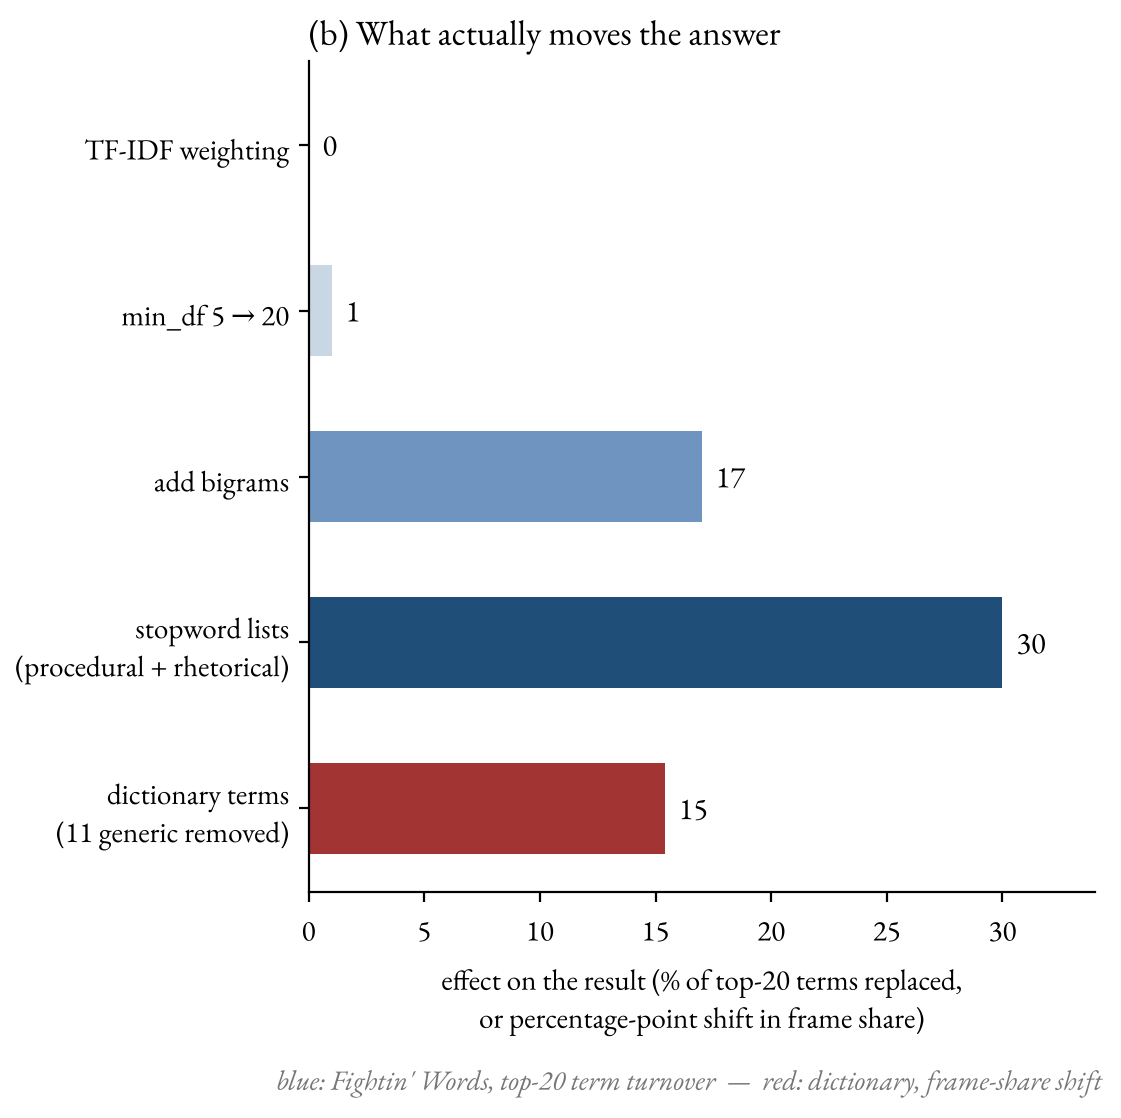

In [10]:
show("what_moves.png")

**Figure 6.** Effect of each analytic decision, measured against its own reference. Blue bars: share of the top-20 Fightin' Words terms replaced (%). Red bar: largest shift in a dictionary frame share (percentage points). The units differ, so compare within a colour.

#### Why the technology frame was inflated

Removing each dictionary word in turn showed that a handful of words carried a lot of weight: *digital* alone moved a frame share by 6.6 points, *data* by 5.8. These are the everyday vocabulary of EU technology policy, not markers of an innovation frame. Without eleven such generic words, the Commission's technology share falls from 35% to 20% and the order of the frames changes. "Technology dominates every institution" was largely produced by a few words.

#### Do the top paragraphs read as the frame?

A high score only means that a frame's words occur often. To check what they mean in context, one of us read the ten highest-scoring paragraphs for each of the seven frames. Six frames pass. Technological innovation fails: its top paragraphs are the same annex list from the AI Act, copied into documents of all three institutions.

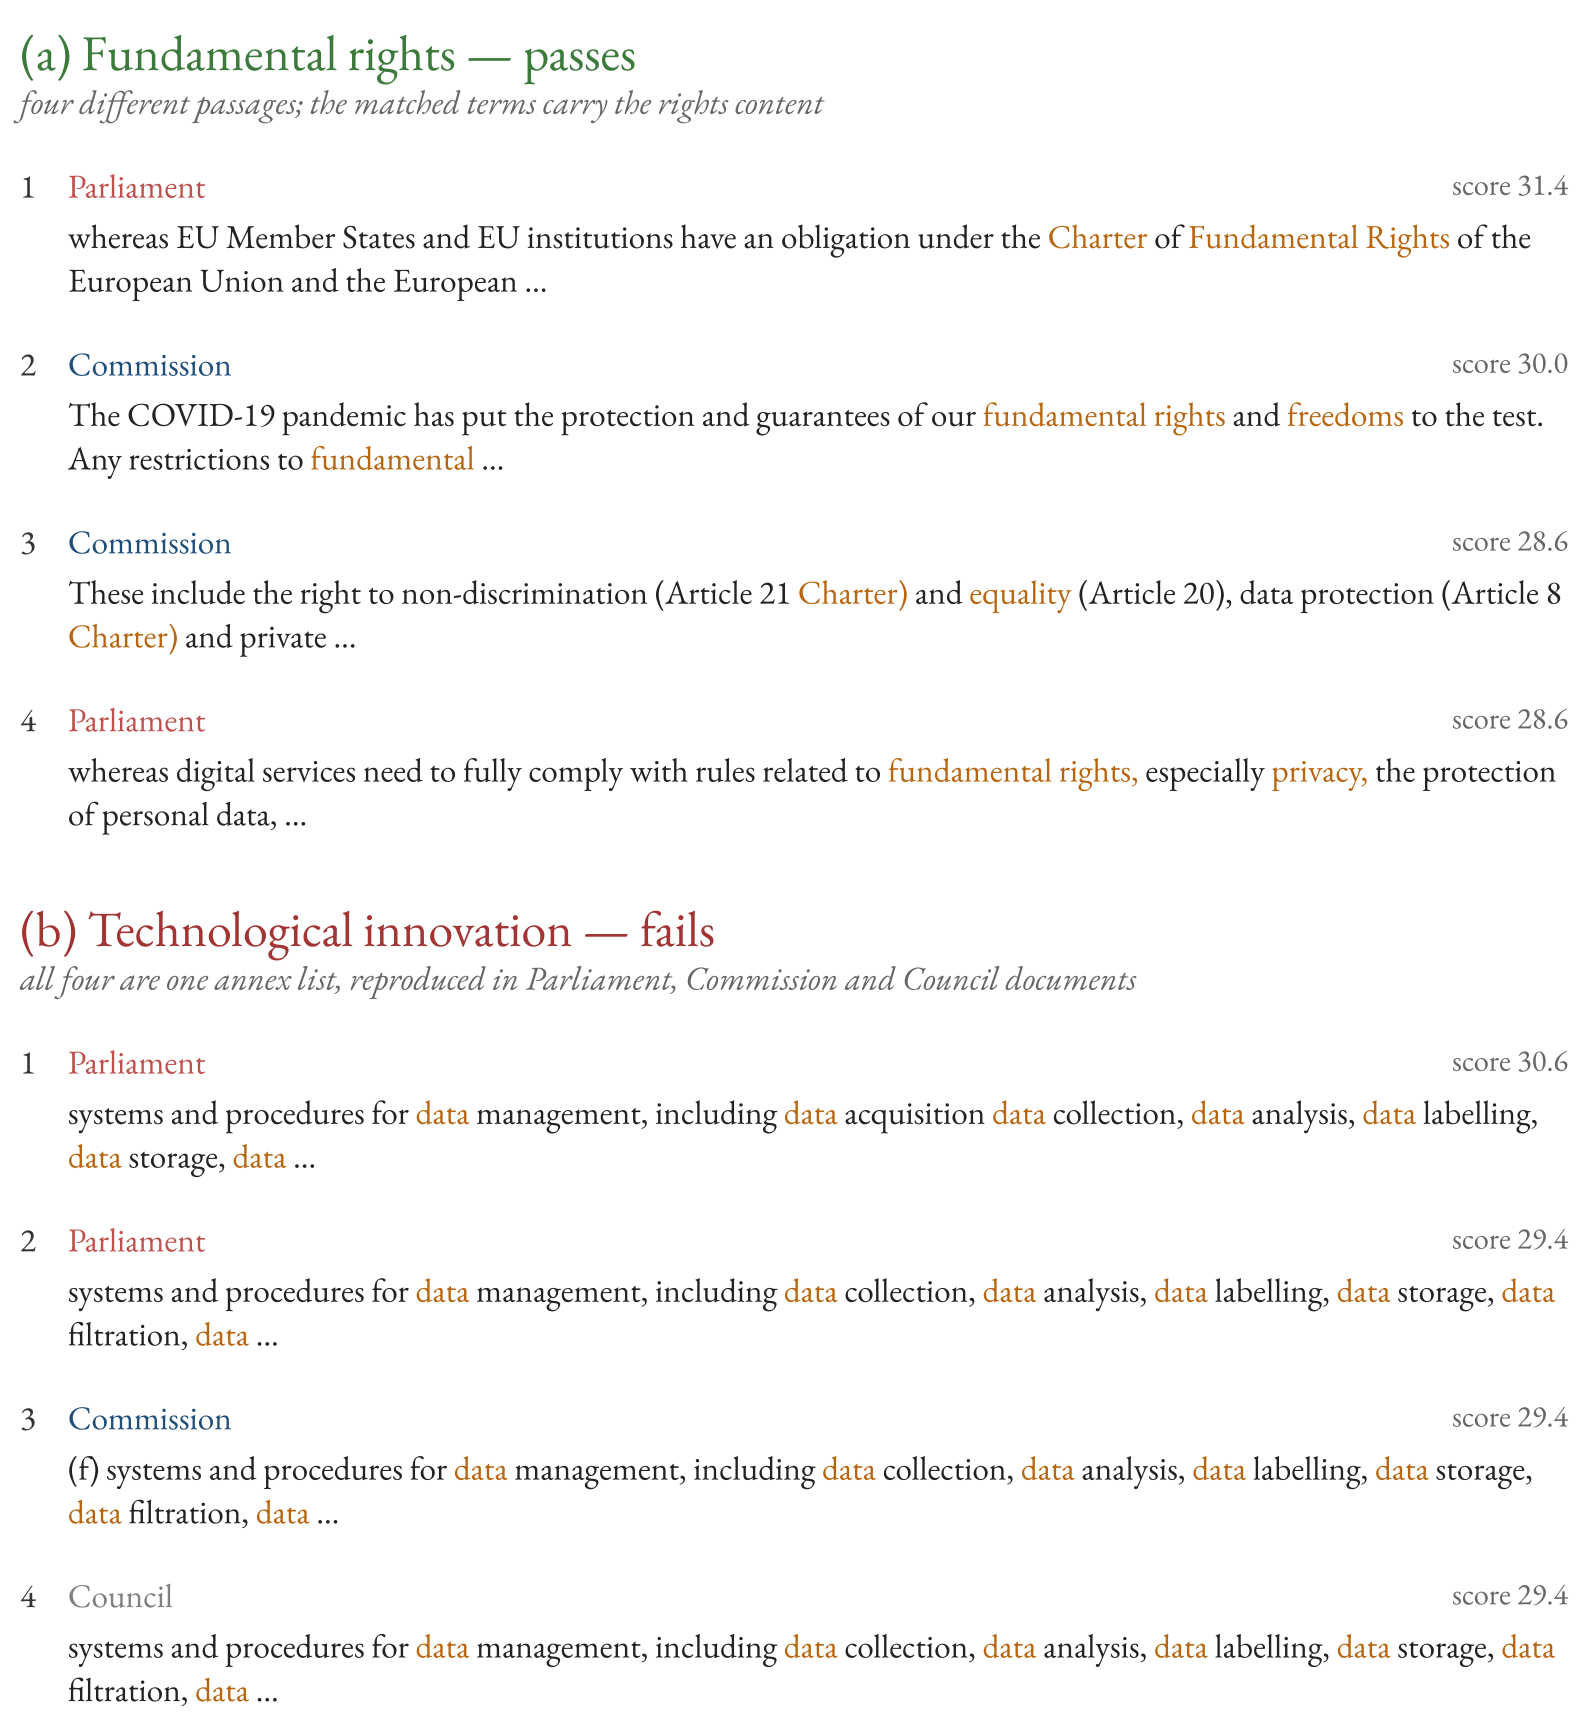

In [11]:
show("face_validity.png", width=900)

**Figure 7.** The four highest-scoring paragraphs for a frame that passes (fundamental rights) and one that fails (technological innovation). Highlighted: words the dictionary counted. Score = frame words per 100 words.

A last check concerned copied text: the Council's compromise texts quote the Commission's proposals, so 17% of Council paragraphs also appear in another institution's documents. Removing every copied paragraph moved no frame share by more than half a percentage point.

## 06 · What this means

### Patterns of role and genre, not of preference

| Expectation                                               | Verdict                                                                          |
|-----------------------------------------------------------|----------------------------------------------------------------------------------|
| H1: institutions differ                                   | Partly supported: two robust differences                                         |
| H2: Commission emphasises governance, economy, technology | Not supported: lowest on governance; its other leads overlap with the Parliament |
| H3: Parliament emphasises rights and consumer protection  | Direction as expected, but not robust                                            |
| H4: Council emphasises security and competitiveness       | Contradicted: the Council is lowest on security; the Commission leads            |

The two differences that hold up both follow from what each institution's job requires it to write. The Commission writes broad strategy documents: 9 of the 10 highest-scoring security paragraphs are the Commission's, on economic security, cybersecurity and supply chains. The Council writes the legal text of the high-risk rules. These are differences in what the institutions write, shaped by role and document genre. They do not show what the institutions prefer.

The broader lesson is methodological. Several differences that looked convincing at first sight were produced by document style, a few common words, or a handful of long documents. Only results that survive several independent checks should be read as findings.

#### Limitations

- **Uneven coverage.** We have about half of the Parliament's in-scope documents and only 28 from the Council, so many intervals are wide.
- **No independent validation.** No one has yet hand-coded a sample of paragraphs to test whether the scores match human judgement; the face-validity reading is a first check by one reader.
- **Model sensitivity.** After one change in text cleaning, only 4 of 10 LDA topics kept a close counterpart; only the high-risk topic is stable throughout.
- **Different genres.** 21 of 28 Council texts are negotiating notes and 33 of 36 Parliament texts are resolutions, so institution and genre cannot be fully separated.

#### What we did not do

Our proposal also planned to compare how similar the institutions' language is and how it changes over time. We dropped both: the Council has only 5 documents from before 2024, too few to compare periods, and the time went into testing whether the main differences hold.

#### Next steps

- Hand-code about 200 paragraphs where the measures are weakest (technology, governance, Council high-risk) and report agreement.
- Recover the missing Parliament opinions and amendment lists.
- Fit a structural topic model with the institution as a covariate (Roberts et al. 2014), so differences are estimated inside the model.
- Compare institutions within a single document genre once more documents are available.

## 07 · Reproducibility

### Every number on this page can be rebuilt

The [GitHub repository](https://github.com/michelle-qyh/SOSC314-Course-Project) contains the collection code, the cleaned corpus with source identifiers, every analysis script, the results as data files, the figures, and our weekly progress reports. The analysis runs offline from the committed corpus in about two minutes:

```bash
pip install -r requirements.txt
python notebooks/03_operationalisation.py      # frame scoring, distinctive words
python notebooks/05_dictionary_diagnostics.py  # term influence, bootstrap, sensitivity
python notebooks/06_face_validity.py           # face validity, copied text
python notebooks/07_figures.py                 # figures
python notebooks/08_topic_figures.py           # topic-model figures, all-topic check
```

The topic models are fitted in two notebooks (`04_topic_modeling.ipynb`, `05_topic_diagnostics.ipynb`), which take much longer because 05 refits the models several times; `08_topic_figures.py` redraws the topic-model figures from their saved results in `reports/week5_topic_diagnostics/`. Rebuilding the corpus from CELLAR needs internet access and the `pdftotext` tool; see the repository README.

EU documents © European Union, reused with attribution under Commission Decision 2011/833/EU.

#### Contributions

**Tim Maurice Steiner:** research design and framing; scope, cleaning and relevance-screening rules; retrieval and extraction code (`collect.py`, `build_corpus.py`) and the Parliament Open Data Portal recovery (`ep_portal.py`); frame dictionary and Fightin' Words (`represent.py`, `measures.py`, `03_operationalisation.py`); dictionary diagnostics and face validity (`diagnostics.py`, `05_dictionary_diagnostics.py`, `06_face_validity.py`); weekly reports and this website.

**Yuhan (Michelle) Qiu:** CELLAR access and the first query and retrieval code (`01_feasibility_test_and_initial_exploration.ipynb`); inventory cross-check, format-availability diagnosis and corpus descriptive statistics (`03_crosscheck_and_descriptive_stats` notebooks); topic models (`04_topic_modeling.ipynb`) and their diagnostics: preprocessing comparison, seed stability, K sensitivity, weighting and bootstrap (`05_topic_diagnostics.ipynb`, `08_topic_figures.py`); topic-model sections of the weekly reports.

#### References

Blei, D. M., Ng, A. Y., & Jordan, M. I. (2003). Latent Dirichlet allocation. *Journal of Machine Learning Research*, 3, 993–1022.

Efron, B., & Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*. Chapman & Hall.

Entman, R. M. (1993). Framing: Toward clarification of a fractured paradigm. *Journal of Communication*, 43(4), 51–58.

Grimmer, J., & Stewart, B. M. (2013). Text as data: The promise and pitfalls of automatic content analysis methods for political texts. *Political Analysis*, 21(3), 267–297.

Lee, D. D., & Seung, H. S. (1999). Learning the parts of objects by non-negative matrix factorization. *Nature*, 401, 788–791.

Monroe, B. L., Colaresi, M. P., & Quinn, K. M. (2008). Fightin' words: Lexical feature selection and evaluation for identifying the content of political conflict. *Political Analysis*, 16(4), 372–403.

Roberts, M. E., Stewart, B. M., Tingley, D., et al. (2014). Structural topic models for open-ended survey responses. *American Journal of Political Science*, 58(4), 1064–1082.

Rochefort, D. A., & Cobb, R. W. (Eds.). (1994). *The Politics of Problem Definition*. University Press of Kansas.

Regulation (EU) 2024/1689 laying down harmonised rules on artificial intelligence (Artificial Intelligence Act). *Official Journal of the European Union*, L, 12 July 2024.

**Use of generative AI.** Yuhan (Michelle) Qiu used Claude (Anthropic) to help write and debug code, including `08_topic_figures.py`, to draft and edit text for the slides and this page, and to check reported numbers against the result files. She checked all output against the data and takes responsibility for it.